In [6]:
## Requirement

import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__,device)


2.11.0+cu130 cuda


In [7]:
## Data Pipeline

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean, std),
])
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(len(train_set), len(test_set))

100%|██████████| 170M/170M [34:06<00:00, 83.3kB/s]


50000 10000


In [8]:
## Baseline_CNN

from torch.nn.modules.pooling import MaxPool1d
from torch.nn.modules.dropout import Dropout


class SmallCNN(nn.Module):
    def __init__(self, dropout = 0.3, num_classes= 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding = 1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32,32,3,padding = 1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(dropout),

            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64),nn.ReLU(),
            nn.Conv2d(64,64,3,padding =1), nn.BatchNorm2d(64),nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(dropout),

            nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128),nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(dropout),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4,256), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,num_classes),
        )
    def forward(self, x):
      return self.classifier(self.features(x))

model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()))

x,y = next(iter(train_loader))
print(model(x.to(device)).shape)

667178
torch.Size([128, 10])


In [9]:
## Validation_Split


from torch.utils.data import Subset

g = torch.Generator().manual_seed(seed)
perm = torch.randperm(50000,generator=g).tolist()
train_idx , val_idx = perm[:45000],perm[45000:]


train_aug = torchvision.datasets.CIFAR10("./data",train =True,download=True,transform=train_tf)
train_clean = torchvision.datasets.CIFAR10("./data",train=True,download=False,transform = test_tf)

train_loader = DataLoader(Subset(train_aug,train_idx),batch_size=128,shuffle=True,num_workers=2,pin_memory=True)
val_loader = DataLoader(Subset(train_clean,val_idx), batch_size=256, shuffle=False, num_workers=2,pin_memory=True)

print(len(train_idx), len(val_idx))

45000 5000


In [10]:
## Training_Loop

def run_epoch(model,loader,criterion,optimizer= None):
  training = optimizer is not None
  model.train() if training else model.eval()
  total_loss,correct,total = 0.0,0,0

  with torch.set_grad_enabled(training):
    for x,y in loader:
      x,y = x.to(device), y .to(device)
      out = model(x)
      loss = criterion(out,y)

      if training:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      total_loss += loss.item()* x.size(0)
      correct +=(out.argmax(1) == y).sum().item()
      total += x.size(0)

  return total_loss / total, correct / total

def fit(model,epochs=20,lr=1e-3, ckpt = "best_baseline.pth"):
  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
  history = {"train_loss": [],"train_acc": [],"val_loss":[],"val_acc": []}
  best_val = 0.0

  for epoch in range(1, epochs+1):
    tr_loss, tr_acc = run_epoch(model,train_loader,criterion,optimizer)
    va_loss ,va_acc = run_epoch(model,val_loader,criterion)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    if va_acc > best_val:
      best_val = va_acc
      torch.save(model.state_dict(),ckpt)

    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} |"
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | lr {optimizer.param_groups[0]['lr']:.5f}")

  return history


In [11]:
model = SmallCNN().to(device)
history = fit(model, epochs=20)

Epoch  1 | train loss 1.703 acc 0.363 |val loss 1.359 acc 0.484 | lr 0.00099
Epoch  2 | train loss 1.373 acc 0.499 |val loss 1.233 acc 0.558 | lr 0.00098
Epoch  3 | train loss 1.218 acc 0.561 |val loss 1.021 acc 0.632 | lr 0.00095
Epoch  4 | train loss 1.139 acc 0.595 |val loss 0.928 acc 0.657 | lr 0.00090
Epoch  5 | train loss 1.073 acc 0.619 |val loss 0.901 acc 0.670 | lr 0.00085
Epoch  6 | train loss 1.009 acc 0.644 |val loss 0.822 acc 0.703 | lr 0.00079
Epoch  7 | train loss 0.978 acc 0.655 |val loss 0.786 acc 0.715 | lr 0.00073
Epoch  8 | train loss 0.934 acc 0.674 |val loss 0.743 acc 0.729 | lr 0.00065
Epoch  9 | train loss 0.899 acc 0.686 |val loss 0.706 acc 0.750 | lr 0.00058
Epoch 10 | train loss 0.867 acc 0.694 |val loss 0.699 acc 0.749 | lr 0.00050
Epoch 11 | train loss 0.840 acc 0.709 |val loss 0.669 acc 0.760 | lr 0.00042
Epoch 12 | train loss 0.827 acc 0.713 |val loss 0.643 acc 0.768 | lr 0.00035
Epoch 13 | train loss 0.805 acc 0.722 |val loss 0.635 acc 0.781 | lr 0.00027

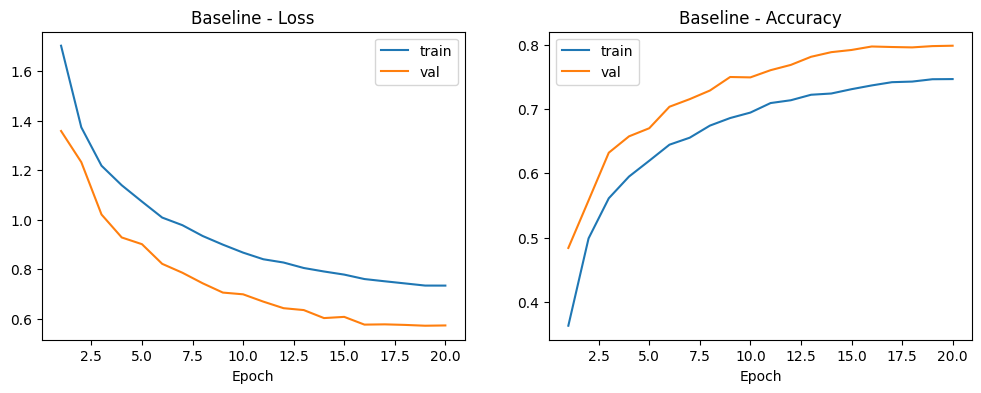

In [13]:
## Visualization

def plot_history(history, title="Baseline"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, history["train_loss"], label="train")
    ax[0].plot(epochs, history["val_loss"], label="val")
    ax[0].set_title(f"{title} - Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()

    ax[1].plot(epochs, history["train_acc"], label="train")
    ax[1].plot(epochs, history["val_acc"], label="val")
    ax[1].set_title(f"{title} - Accuracy")
    ax[1].set_xlabel("Epoch")
    ax[1].legend()
    plt.show()

plot_history(history)

In [14]:
model.load_state_dict(torch.load("best_baseline.pth"))
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = run_epoch(model, test_loader, criterion)
print(f"Test loss {test_loss:.3f} | Test accuracy {test_acc:.3f}")

baseline_history = history
baseline_test_acc = test_acc

Test loss 0.586 | Test accuracy 0.795


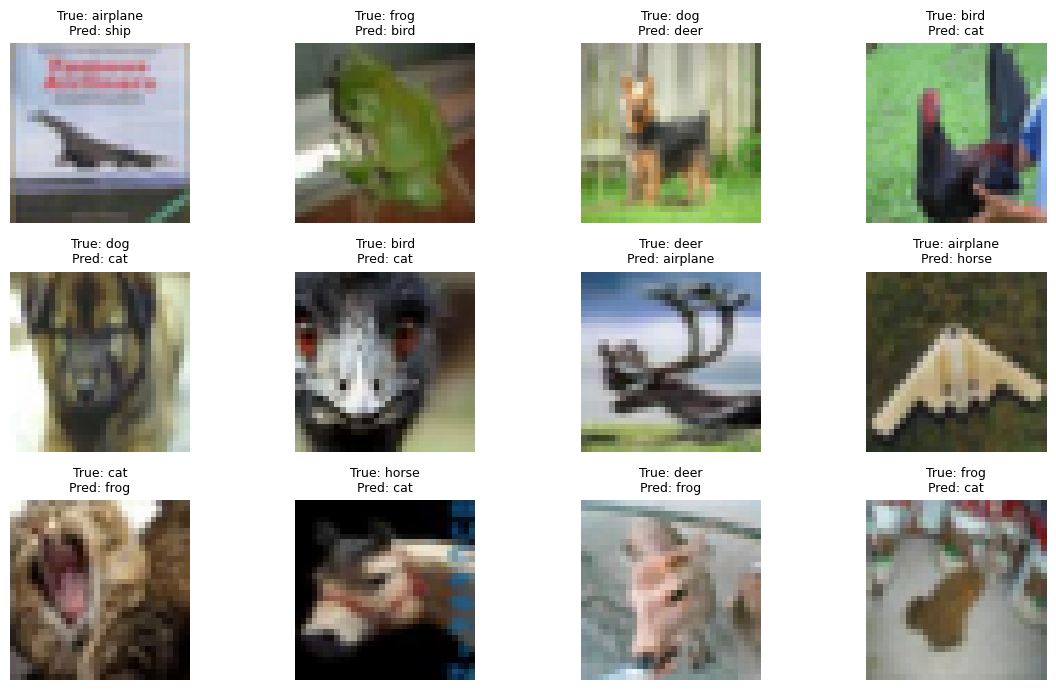

In [15]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

def show_misclassified(model, loader, n=12):
    model.eval()
    wrong = []
    with torch.no_grad():
        for x, y in loader:
            preds = model(x.to(device)).argmax(1).cpu()
            for img, true, pred in zip(x, y, preds):
                if true != pred:
                    wrong.append((img, true.item(), pred.item()))
            if len(wrong) >= n:
                break

    plt.figure(figsize=(12, 7))
    for i, (img, true, pred) in enumerate(wrong[:n]):
        img = img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
        plt.subplot(3, 4, i + 1)
        plt.imshow(img.permute(1, 2, 0).clamp(0, 1))
        plt.title(f"True: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]}", fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_misclassified(model, test_loader)

In [16]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return F.relu(out)


class ResCNN(nn.Module):
    def __init__(self, dropout=0.3, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(),
        )
        self.layers = nn.Sequential(
            ResidualBlock(32, 32),
            ResidualBlock(32, 64, stride=2),     # 32x32 -> 16x16
            nn.Dropout(dropout),
            ResidualBlock(64, 128, stride=2),    # 16x16 -> 8x8
            nn.Dropout(dropout),
            ResidualBlock(128, 128, stride=2),   # 8x8 -> 4x4
            nn.Dropout(dropout),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.layers(self.stem(x)))

torch.manual_seed(seed)
model_res = ResCNN().to(device)
print(sum(p.numel() for p in model_res.parameters()))
print(model_res(next(iter(train_loader))[0].to(device)).shape)

620714
torch.Size([128, 10])


In [17]:
## Training

res_history = fit(model_res, epochs=20, ckpt="best_resnet.pth")

Epoch  1 | train loss 1.563 acc 0.416 |val loss 1.190 acc 0.565 | lr 0.00099
Epoch  2 | train loss 1.184 acc 0.576 |val loss 1.244 acc 0.584 | lr 0.00098
Epoch  3 | train loss 1.031 acc 0.635 |val loss 0.996 acc 0.648 | lr 0.00095
Epoch  4 | train loss 0.942 acc 0.670 |val loss 0.859 acc 0.691 | lr 0.00090
Epoch  5 | train loss 0.861 acc 0.700 |val loss 0.799 acc 0.712 | lr 0.00085
Epoch  6 | train loss 0.793 acc 0.725 |val loss 0.710 acc 0.749 | lr 0.00079
Epoch  7 | train loss 0.737 acc 0.749 |val loss 0.736 acc 0.744 | lr 0.00073
Epoch  8 | train loss 0.684 acc 0.765 |val loss 0.632 acc 0.780 | lr 0.00065
Epoch  9 | train loss 0.644 acc 0.780 |val loss 0.581 acc 0.800 | lr 0.00058
Epoch 10 | train loss 0.606 acc 0.794 |val loss 0.609 acc 0.796 | lr 0.00050
Epoch 11 | train loss 0.576 acc 0.804 |val loss 0.575 acc 0.807 | lr 0.00042
Epoch 12 | train loss 0.544 acc 0.816 |val loss 0.502 acc 0.829 | lr 0.00035
Epoch 13 | train loss 0.526 acc 0.820 |val loss 0.480 acc 0.833 | lr 0.00027

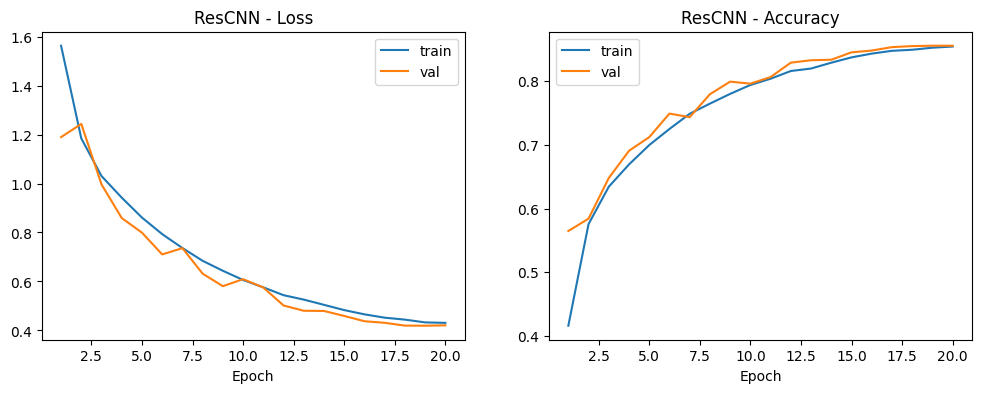

Baseline test accuracy: 0.795
ResCNN test accuracy:   0.854


In [18]:
## Compare

plot_history(res_history, "ResCNN")

model_res.load_state_dict(torch.load("best_resnet.pth"))
res_test_loss, res_test_acc = run_epoch(model_res, test_loader, nn.CrossEntropyLoss())

print(f"Baseline test accuracy: {baseline_test_acc:.3f}")
print(f"ResCNN test accuracy:   {res_test_acc:.3f}")

In [19]:
import torch, torchvision, numpy, matplotlib
print(torch.__version__, torchvision.__version__, numpy.__version__, matplotlib.__version__)

2.11.0+cu130 0.26.0+cu130 2.1.3 3.10.0
